In [ ]:
import pandas as pd

# A verified, live URL for Bitcoin data
url = "https://raw.githubusercontent.com/Yrzxiong/Bitcoin-Dataset/master/bitcoin_dataset.csv"

try:
    # Load the data directly into Colab
    df = pd.read_csv(url)
    print("Dataset Loaded Successfully! 🎉")
    print(f"Dataset Shape: {df.shape} (Rows, Columns)\n")

    # Display the first 5 rows
    display(df.head())
except Exception as e:
    print(f"An error occurred: {e}")

Dataset Loaded Successfully! 🎉
Dataset Shape: (2906, 24) (Rows, Columns)



,Date,btc_market_price,btc_total_bitcoins,btc_market_cap,btc_trade_volume,btc_blocks_size,btc_avg_block_size,btc_n_orphaned_blocks,btc_n_transactions_per_block,btc_median_confirmation_time,...,btc_cost_per_transaction_percent,btc_cost_per_transaction,btc_n_unique_addresses,btc_n_transactions,btc_n_transactions_total,btc_n_transactions_excluding_popular,btc_n_transactions_excluding_chains_longer_than_100,btc_output_volume,btc_estimated_transaction_volume,btc_estimated_transaction_volume_usd
0,2/17/2010 0:00,0.0,2043200.0,0.0,0.0,0.0,0.000235,0,1.0,0.0,...,31.781022,0.0,241,244,41240,244,244,65173.13,36500.0,0.0
1,2/18/2010 0:00,0.0,2054650.0,0.0,0.0,0.0,0.000241,0,1.0,0.0,...,154.463801,0.0,234,235,41475,235,235,18911.74,7413.0,0.0
2,2/19/2010 0:00,0.0,2063600.0,0.0,0.0,0.0,0.000228,0,1.0,0.0,...,1278.516635,0.0,185,183,41658,183,183,9749.98,700.0,0.0
3,2/20/2010 0:00,0.0,2074700.0,0.0,0.0,0.0,0.000218,0,1.0,0.0,...,22186.687990,0.0,224,224,41882,224,224,11150.03,50.0,0.0
4,2/21/2010 0:00,0.0,2085400.0,0.0,0.0,0.0,0.000234,0,1.0,0.0,...,689.179876,0.0,218,218,42100,218,218,12266.83,1553.0,0.0


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2906 entries, 0 to 2905
Data columns (total 24 columns):
 #   Column                                               Non-Null Count  Dtype  
---  ------                                               --------------  -----  
 0   Date                                                 2906 non-null   object 
 1   btc_market_price                                     2906 non-null   float64
 2   btc_total_bitcoins                                   2879 non-null   float64
 3   btc_market_cap                                       2906 non-null   float64
 4   btc_trade_volume                                     2885 non-null   float64
 5   btc_blocks_size                                      2877 non-null   float64
 6   btc_avg_block_size                                   2906 non-null   float64
 7   btc_n_orphaned_blocks                                2906 non-null   int64  
 8   btc_n_transactions_per_block                         2906 non-null  

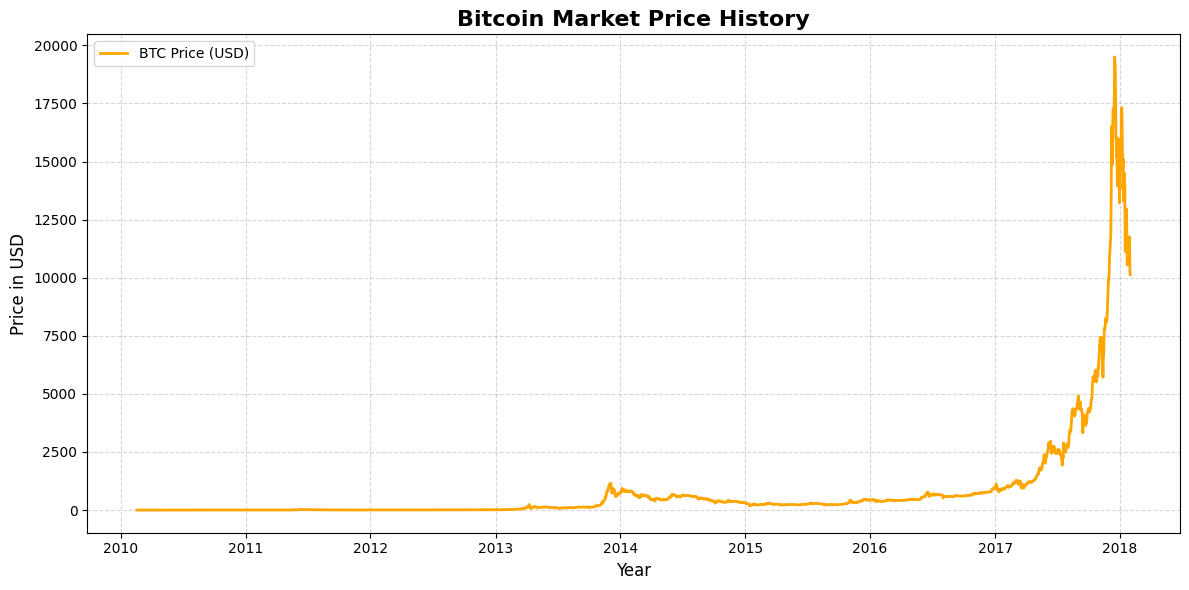

In [ ]:
import matplotlib.pyplot as plt

# 1. Convert the 'Date' column into actual dates Pandas can understand
df['Date'] = pd.to_datetime(df['Date'])

# 2. Setup the size of your graph
plt.figure(figsize=(12, 6))

# 3. Plot Date on the X-axis and btc_market_price on the Y-axis
plt.plot(df['Date'], df['btc_market_price'], color='orange', linewidth=2, label='BTC Price (USD)')

# 4. Make the chart look clean and professional
plt.title('Bitcoin Market Price History', fontsize=16, fontweight='bold')
plt.xlabel('Year', fontsize=12)
plt.ylabel('Price in USD', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left')

# 5. Render the plot
plt.tight_layout()
plt.show()

In [ ]:
# 1. Check how many missing values are in each column
print("Missing values per column before cleaning:")
print(df.isnull().sum())

# 2. A quick and easy way to handle missing values for beginners:
# Fill any missing values with the mean (average) of that column
df = df.fillna(df.mean(numeric_only=True))

print("\nData cleaned! Missing values after filling:")
print(df.isnull().sum().sum())

Missing values per column before cleaning:
Date                                                    0
btc_market_price                                        0
btc_total_bitcoins                                     27
btc_market_cap                                          0
btc_trade_volume                                       21
btc_blocks_size                                        29
btc_avg_block_size                                      0
btc_n_orphaned_blocks                                   0
btc_n_transactions_per_block                            0
btc_median_confirmation_time                           12
btc_hash_rate                                           0
btc_difficulty                                         16
btc_miners_revenue                                      0
btc_transaction_fees                                   10
btc_cost_per_transaction_percent                        0
btc_cost_per_transaction                                0
btc_n_unique_addresses       

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# 1. Define Features (X) and Target Variable (y)
# We drop 'Date' because text dates break linear equations, and 'btc_market_price' because it's what we want to predict.
X = df.drop(columns=['Date', 'btc_market_price'])
y = df['btc_market_price']

# 2. Split into 80% Training and 20% Testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize the AI Model
model = LinearRegression()

# 4. Train the model (The "Learning" phase)
model.fit(X_train, y_train)

# 5. Make predictions on the Test data (The "Exam" phase)
predictions = model.predict(X_test)

# 6. Score the model using R-squared (R²)
# 1.0 is a perfect score, 0.0 means the model is just blindly guessing.
score = r2_score(y_test, predictions)

print(f"Model Training Complete! ")
print(f"Your Model's R² Score is: {score:.4f}")

Model Training Complete! 🎉
Your Model's R² Score is: 0.9999
